# IoU-based evaluation of LLM argument spans (strict ECHR prompts)

Same scoring idea as the `Scorer` / `eval_anchor` / `eval_label` code, with one change: a system span and a gold span count as a
match when their **character IoU is at least `THRESHOLD`**, instead of requiring identical `(start, end)`.

- Matches are **one-to-one** within each prompt (a gold span can be matched by at most one system span, and the other way round).
  Among eligible pairs the matching first maximises the number of pairs, then the total IoU.
- `c` (correct) = number of matched pairs, `s` = number of system spans, `g` = number of gold spans, then `p = c/s`, `r = c/g`, `f` as before.
- **anchor**: spans only (label ignored). **label**: per label, then `total` where a pair must also have the same label.
- Positions are character offsets inside the prompt's document text, as in both JSON files.

Files needed next to this notebook: `strict_echr_llm_outputs.json` and `gold_strict_echr.json`.

In [5]:
import json, re
from typing import Dict, List, Set, Tuple
import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment

LLM_PATH  = "E:\\Docs\\intern\\AAintern\\legal\\experimental_setup\\strict_echr_llm_outputs.json"
GOLD_PATH = "E:\\Docs\\intern\\AAintern\\legal\\experimental_setup\\gold_strict_echr.json"

THRESHOLD = 0.5                       # the IoU threshold "a"
SWEEP     = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]   # thresholds for the sweep table

# Prompts to evaluate. Gold for the 700 and 1000-word prompts was derived from the 2000-word gold
# (same document start, spans cut at the end of each prompt), so drop them here if you only want the given gold.
PROMPTS = ["strict_16_echr_labels_700words", "strict_16_echr_labels_1000words", "strict_16_echr_labels_2000words"]

# Runs that produced no output because of a GPU out-of-memory error, not because of model quality.
# They are left out so they do not count as zero recall. Set to set() to include them.
SKIP_RUNS = {("Raazi29/Nyaya-Llama-3.1-8B-Indian-Legal", "strict_16_echr_labels_2000words")}

# Spans the model wrote but that could not be found in the document (text_position is null) cannot be matched by IoU.
# True: count them as system spans (false positives). False: ignore them.
COUNT_UNLOCATED_AS_FP = True

ALLOWED_LABELS = [
    "Procedural arguments—Non contestation by the parties", "Method of interpretation—Textual interpretation",
    "Method of interpretation—Historical interpretation", "Method of interpretation—Systematic interpretation",
    "Method of interpretation—Teleological interpretation", "Method of interpretation—Comparative law",
    "Test of the principle of proportionality—Legal basis", "Test of the principle of proportionality—Legitimate purpose",
    "Test of the principle of proportionality—Suitability", "Test of the principle of proportionality—Necessity/Proportionality",
    "Institutional arguments—Overruling", "Institutional arguments—Distinguishing",
    "Institutional arguments—Margin of Appreciation", "Precedents of the ECHR", "Decision of the ECHR",
    "Application to the concrete case",
]

In [6]:
def _key(s): return re.sub(r"[^a-z0-9]", "", s.lower())
_ALLOWED = {_key(l): l for l in ALLOWED_LABELS}
unmatched_labels = []

def canonical_label(label: str) -> str:
    """Map a model label to one of the 16 allowed labels (case, dash style and a trailing ': definition' are ignored)."""
    k = _key(label)
    if k in _ALLOWED: return _ALLOWED[k]
    for ak, al in sorted(_ALLOWED.items(), key=lambda x: -len(x[0])):
        if k.startswith(ak): return al
    unmatched_labels.append(label)
    return label

def span_iou(a: Tuple[int, int], b: Tuple[int, int]) -> float:
    inter = max(0, min(a[1], b[1]) - max(a[0], b[0]))
    union = (a[1] - a[0]) + (b[1] - b[0]) - inter
    return inter / union if union > 0 else 0.0

def match_spans(system: List[Tuple[int, int]], gold: List[Tuple[int, int]], thr: float):
    """One-to-one matching. Eligible pair: IoU >= thr (and > 0). Maximises #pairs first, then total IoU."""
    if not system or not gold: return []
    iou = np.array([[span_iou(s, g) for g in gold] for s in system])
    eligible = (iou >= thr) & (iou > 0)
    if not eligible.any(): return []
    weight = np.where(eligible, 1.0 + iou, 0.0)
    rows, cols = linear_sum_assignment(-weight)
    return [(i, j, iou[i, j]) for i, j in zip(rows, cols) if eligible[i, j]]

In [7]:
class Scorer:
    def __init__(self):
        self.s = 0
        self.g = 0
        self.c = 0
        return

    def add(self, system: Set[Tuple], gold: Set[Tuple]):          # original exact-match version, kept for reference
        self.s += len(system)
        self.g += len(gold)
        self.c += len(gold & system)
        return

    def add_counts(self, n_system: int, n_gold: int, n_correct: int):   # IoU version: counts come from the matching
        self.s += n_system
        self.g += n_gold
        self.c += n_correct
        return

    @property
    def p(self):
        return self.c / self.s if self.s else 0.

    @property
    def r(self):
        return self.c / self.g if self.g else 0.

    @property
    def f(self):
        p = self.p
        r = self.r
        return (2. * p * r) / (p + r) if p + r > 0 else 0.0

    def dump(self):
        return {'g': self.g, 's': self.s, 'c': self.c, 'p': self.p, 'r': self.r, 'f': self.f}

In [8]:
# ---- load the two JSON files and convert them to the {"id", "nodes": [{"label", "anchors": [{"from","to"}]}]} layout ----
llm_data  = json.load(open(LLM_PATH, encoding="utf-8"))
gold_data = json.load(open(GOLD_PATH, encoding="utf-8"))

def to_mrp(prompt_id: str, spans: List[Dict], is_gold: bool) -> Dict:
    nodes = []
    for sp in spans:
        pos = sp.get("text_position")
        if pos is None:
            if is_gold or not COUNT_UNLOCATED_AS_FP: continue
            anchors = []                                          # system span that cannot be located: never matches
        else:
            anchors = [{"from": pos[0], "to": pos[1]}]
        nodes.append({"label": canonical_label(sp["label"]), "anchors": anchors})
    return {"id": prompt_id, "nodes": nodes}

gold_mrps = {p["prompt_name"]: to_mrp(p["prompt_name"], p["gold_output"], True) for p in gold_data}
system_mrps = {}                                                  # llm_name -> {prompt_name: mrp}
for entry in llm_data:
    system_mrps[entry["llm_name"]] = {
        p["prompt_name"]: to_mrp(p["prompt_name"], p["llm_output"], False) for p in entry["prompts"]}

def aligned(llm: str, prompts=None):
    prompts = [p for p in (prompts or PROMPTS) if (llm, p) not in SKIP_RUNS]
    return [system_mrps[llm][p] for p in prompts], [gold_mrps[p] for p in prompts]

print("LLMs:", list(system_mrps))
print("Gold spans per prompt:", {p: len(m["nodes"]) for p, m in gold_mrps.items()})
print("System labels not in the 16 allowed labels:", len(unmatched_labels), sorted(set(unmatched_labels))[:5])

LLMs: ['Qwen/Qwen2.5-7B-Instruct', 'Qwen/Qwen3-8B-Base', 'mistralai/Mistral-7B-v0.3', 'AdaptLLM/law-LLM', 'goasty/Qwen3-4B-Indian-Law', 'RMani1/indian-legal-qwen-lora', 'CHKishore/indic-criminal-law-llm-v1', 'Raazi29/Nyaya-Llama-3.1-8B-Indian-Legal']
Gold spans per prompt: {'strict_16_echr_labels_700words': 7, 'strict_16_echr_labels_1000words': 10, 'strict_16_echr_labels_2000words': 21}
System labels not in the 16 allowed labels: 0 []


In [9]:
def _pairs(s_nodes, g_nodes, thr):
    """Matches between two node lists (already filtered, e.g. to one label)."""
    s_idx = [i for i, n in enumerate(s_nodes) if n["anchors"]]
    s_sp = [(s_nodes[i]["anchors"][0]["from"], s_nodes[i]["anchors"][0]["to"]) for i in s_idx]
    g_sp = [(n["anchors"][0]["from"], n["anchors"][0]["to"]) for n in g_nodes]
    return match_spans(s_sp, g_sp, thr)

def eval_anchor(s_mrps: List[Dict], g_mrps: List[Dict], thr: float = THRESHOLD) -> Dict:
    scorer = Scorer()
    for s_mrp, g_mrp in zip(s_mrps, g_mrps):
        scorer.add_counts(len(s_mrp["nodes"]), len(g_mrp["nodes"]), len(_pairs(s_mrp["nodes"], g_mrp["nodes"], thr)))
    return scorer.dump()

def eval_label(s_mrps: List[Dict], g_mrps: List[Dict], thr: float = THRESHOLD) -> Dict:
    labels = set()
    for g_mrp in g_mrps:
        labels |= set([n["label"] for n in g_mrp["nodes"] if "label" in n])
    label_scores = dict()
    for label in labels:
        scorer = Scorer()
        for s_mrp, g_mrp in zip(s_mrps, g_mrps):
            s_nodes = [n for n in s_mrp["nodes"] if "label" in n and n["label"] == label]
            g_nodes = [n for n in g_mrp["nodes"] if "label" in n and n["label"] == label]
            scorer.add_counts(len(s_nodes), len(g_nodes), len(_pairs(s_nodes, g_nodes, thr)))
        label_scores[label] = scorer.dump()

    # total: a pair must have the same label (matching is done inside each label)
    scorer = Scorer()
    for s_mrp, g_mrp in zip(s_mrps, g_mrps):
        c = 0
        for label in labels:
            s_nodes = [n for n in s_mrp["nodes"] if n.get("label") == label]
            g_nodes = [n for n in g_mrp["nodes"] if n.get("label") == label]
            c += len(_pairs(s_nodes, g_nodes, thr))
        scorer.add_counts(len([n for n in s_mrp["nodes"] if "label" in n]),
                          len([n for n in g_mrp["nodes"] if "label" in n]), c)
    label_scores["total"] = scorer.dump()
    return label_scores

## Results at the chosen threshold

In [10]:
rows = []
for llm in system_mrps:
    s, g = aligned(llm)
    a, l = eval_anchor(s, g), eval_label(s, g)["total"]
    rows.append({"llm": llm, "runs": len(s), "g": a["g"], "s": a["s"],
                 "span_c": a["c"], "span_P": a["p"], "span_R": a["r"], "span_F1": a["f"],
                 "label_c": l["c"], "label_P": l["p"], "label_R": l["r"], "label_F1": l["f"]})
summary = pd.DataFrame(rows).set_index("llm")
print(f"IoU threshold a = {THRESHOLD}; prompts = {[p.split('_')[-1] for p in PROMPTS]}")
summary.round(3)

IoU threshold a = 0.5; prompts = ['700words', '1000words', '2000words']


,runs,g,s,span_c,span_P,span_R,span_F1,label_c,label_P,label_R,label_F1
llm,,,,,,,,,,,
Qwen/Qwen2.5-7B-Instruct,3,38,59,13,0.220,0.342,0.268,10,0.169,0.263,0.206
Qwen/Qwen3-8B-Base,3,38,47,9,0.191,0.237,0.212,8,0.170,0.211,0.188
mistralai/Mistral-7B-v0.3,3,38,2,0,0.000,0.000,0.000,0,0.000,0.000,0.000
AdaptLLM/law-LLM,3,38,0,0,0.000,0.000,0.000,0,0.000,0.000,0.000
goasty/Qwen3-4B-Indian-Law,3,38,54,10,0.185,0.263,0.217,0,0.000,0.000,0.000
RMani1/indian-legal-qwen-lora,3,38,32,9,0.281,0.237,0.257,7,0.219,0.184,0.200
CHKishore/indic-criminal-law-llm-v1,3,38,0,0,0.000,0.000,0.000,0,0.000,0.000,0.000
Raazi29/Nyaya-Llama-3.1-8B-Indian-Legal,2,17,21,4,0.190,0.235,0.211,3,0.143,0.176,0.158


## Per prompt

In [11]:
rows = []
for llm in system_mrps:
    for p in PROMPTS:
        if (llm, p) in SKIP_RUNS: continue
        s, g = [system_mrps[llm][p]], [gold_mrps[p]]
        a, l = eval_anchor(s, g), eval_label(s, g)["total"]
        rows.append({"llm": llm, "prompt": p.split("_")[-1], "g": a["g"], "s": a["s"],
                     "span_P": a["p"], "span_R": a["r"], "span_F1": a["f"], "label_P": l["p"], "label_R": l["r"], "label_F1": l["f"]})
pd.DataFrame(rows).set_index(["llm", "prompt"]).round(3)

g   s  span_P  span_R  \
llm                                     prompt                              
Qwen/Qwen2.5-7B-Instruct                700words    7  13   0.385   0.714   
                                        1000words  10  19   0.211   0.400   
                                        2000words  21  27   0.148   0.190   
Qwen/Qwen3-8B-Base                      700words    7  17   0.176   0.429   
                                        1000words  10   0   0.000   0.000   
                                        2000words  21  30   0.200   0.286   
mistralai/Mistral-7B-v0.3               700words    7   2   0.000   0.000   
                                        1000words  10   0   0.000   0.000   
                                        2000words  21   0   0.000   0.000   
AdaptLLM/law-LLM                        700words    7   0   0.000   0.000   
                                        1000words  10   0   0.000   0.000   
                                        2000words  21   0   0.000   0.000   
goasty/Qwen3-4B-Indian-Law              700words    7  18   0.000   0.000   
                                        1000words  10  22   0.227   0.500   
                                        2000words  21  14   0.357   0.238   
RMani1/indian-legal-qwen-lora           700words    7  16   0.312   0.714   
                                        1000words  10   5   0.400   0.200   
                                        2000words  21  11   0.182   0.095   
CHKishore/indic-criminal-law-llm-v1     700words    7   0   0.000   0.000   
                                        1000words  10   0   0.000   0.000   
                                        2000words  21   0   0.000   0.000   
Raazi29/Nyaya-Llama-3.1-8B-Indian-Legal 700words    7   1   0.000   0.000   
                                        1000words  10  20   0.200   0.400   

                                                   span_F1  label_P  label_R  \
llm                                     prompt                                 
Qwen/Qwen2.5-7B-Instruct                700words     0.500    0.231    0.429   
                                        1000words    0.276    0.211    0.400   
                                        2000words    0.167    0.111    0.143   
Qwen/Qwen3-8B-Base                      700words     0.250    0.118    0.286   
                                        1000words    0.000    0.000    0.000   
                                        2000words    0.235    0.200    0.286   
mistralai/Mistral-7B-v0.3               700words     0.000    0.000    0.000   
                                        1000words    0.000    0.000    0.000   
                                        2000words    0.000    0.000    0.000   
AdaptLLM/law-LLM                        700words     0.000    0.000    0.000   
                                        1000words    0.000    0.000    0.000   
                                        2000words    0.000    0.000    0.000   
goasty/Qwen3-4B-Indian-Law              700words     0.000    0.000    0.000   
                                        1000words    0.312    0.000    0.000   
                                        2000words    0.286    0.000    0.000   
RMani1/indian-legal-qwen-lora           700words     0.435    0.188    0.429   
                                        1000words    0.267    0.400    0.200   
                                        2000words    0.125    0.182    0.095   
CHKishore/indic-criminal-law-llm-v1     700words     0.000    0.000    0.000   
                                        1000words    0.000    0.000    0.000   
                                        2000words    0.000    0.000    0.000   
Raazi29/Nyaya-Llama-3.1-8B-Indian-Legal 700words     0.000    0.000    0.000   
                                        1000words    0.267    0.150    0.300   

                                                   label_F1  
llm                                     prompt               
Q

## Per label (one table per LLM, all prompts pooled)

In [12]:
def per_label_table(llm, thr=THRESHOLD):
    s, g = aligned(llm)
    sc = eval_label(s, g, thr)
    df = pd.DataFrame(sc).T[["g", "s", "c", "p", "r", "f"]]
    return df.sort_values("g", ascending=False).round(3)

for llm in system_mrps:
    print("\n==", llm)
    display(per_label_table(llm))


== Qwen/Qwen2.5-7B-Instruct


,g,s,c,p,r,f
total,38.0,59.0,10.0,0.169,0.263,0.206
Application to the concrete case,25.0,58.0,10.0,0.172,0.400,0.241
Test of the principle of proportionality—Necessity/Proportionality,6.0,0.0,0.0,0.000,0.000,0.000
Precedents of the ECHR,4.0,0.0,0.0,0.000,0.000,0.000
Decision of the ECHR,3.0,0.0,0.0,0.000,0.000,0.000



== Qwen/Qwen3-8B-Base


,g,s,c,p,r,f
total,38.0,47.0,8.0,0.17,0.211,0.188
Application to the concrete case,25.0,47.0,8.0,0.17,0.320,0.222
Test of the principle of proportionality—Necessity/Proportionality,6.0,0.0,0.0,0.00,0.000,0.000
Precedents of the ECHR,4.0,0.0,0.0,0.00,0.000,0.000
Decision of the ECHR,3.0,0.0,0.0,0.00,0.000,0.000



== mistralai/Mistral-7B-v0.3


,g,s,c,p,r,f
total,38.0,2.0,0.0,0.0,0.0,0.0
Application to the concrete case,25.0,1.0,0.0,0.0,0.0,0.0
Test of the principle of proportionality—Necessity/Proportionality,6.0,0.0,0.0,0.0,0.0,0.0
Precedents of the ECHR,4.0,0.0,0.0,0.0,0.0,0.0
Decision of the ECHR,3.0,1.0,0.0,0.0,0.0,0.0


... (6 outputs left out)


== CHKishore/indic-criminal-law-llm-v1


,g,s,c,p,r,f
total,38.0,0.0,0.0,0.0,0.0,0.0
Application to the concrete case,25.0,0.0,0.0,0.0,0.0,0.0
Test of the principle of proportionality—Necessity/Proportionality,6.0,0.0,0.0,0.0,0.0,0.0
Precedents of the ECHR,4.0,0.0,0.0,0.0,0.0,0.0
Decision of the ECHR,3.0,0.0,0.0,0.0,0.0,0.0



== Raazi29/Nyaya-Llama-3.1-8B-Indian-Legal


,g,s,c,p,r,f
total,17.0,21.0,3.0,0.143,0.176,0.158
Application to the concrete case,11.0,21.0,3.0,0.143,0.273,0.187
Test of the principle of proportionality—Necessity/Proportionality,4.0,0.0,0.0,0.000,0.000,0.000
Decision of the ECHR,2.0,0.0,0.0,0.000,0.000,0.000


## Threshold sweep (F1)

In [13]:
sweep_span, sweep_label = {}, {}
for llm in system_mrps:
    s, g = aligned(llm)
    sweep_span[llm]  = [eval_anchor(s, g, t)["f"] for t in SWEEP]
    sweep_label[llm] = [eval_label(s, g, t)["total"]["f"] for t in SWEEP]
print("Span F1 (label ignored)");  display(pd.DataFrame(sweep_span, index=SWEEP).T.round(3))
print("Span + label F1");          display(pd.DataFrame(sweep_label, index=SWEEP).T.round(3))

Span F1 (label ignored)


,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0
Qwen/Qwen2.5-7B-Instruct,0.557,0.536,0.515,0.433,0.268,0.247,0.186,0.144,0.144,0.082
Qwen/Qwen3-8B-Base,0.400,0.376,0.329,0.259,0.212,0.188,0.141,0.118,0.118,0.094
mistralai/Mistral-7B-v0.3,0.100,0.050,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
AdaptLLM/law-LLM,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
goasty/Qwen3-4B-Indian-Law,0.283,0.261,0.239,0.217,0.217,0.196,0.174,0.174,0.174,0.174
RMani1/indian-legal-qwen-lora,0.400,0.400,0.400,0.371,0.257,0.229,0.143,0.143,0.143,0.057
CHKishore/indic-criminal-law-llm-v1,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Raazi29/Nyaya-Llama-3.1-8B-Indian-Legal,0.474,0.474,0.421,0.316,0.211,0.158,0.158,0.105,0.105,0.105


Span + label F1


,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0
Qwen/Qwen2.5-7B-Instruct,0.392,0.371,0.371,0.309,0.206,0.206,0.165,0.124,0.124,0.082
Qwen/Qwen3-8B-Base,0.306,0.282,0.282,0.235,0.188,0.188,0.141,0.118,0.118,0.094
mistralai/Mistral-7B-v0.3,0.050,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
AdaptLLM/law-LLM,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
goasty/Qwen3-4B-Indian-Law,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
RMani1/indian-legal-qwen-lora,0.314,0.314,0.314,0.286,0.200,0.200,0.114,0.114,0.114,0.057
CHKishore/indic-criminal-law-llm-v1,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Raazi29/Nyaya-Llama-3.1-8B-Indian-Legal,0.368,0.368,0.316,0.263,0.158,0.158,0.158,0.105,0.105,0.105


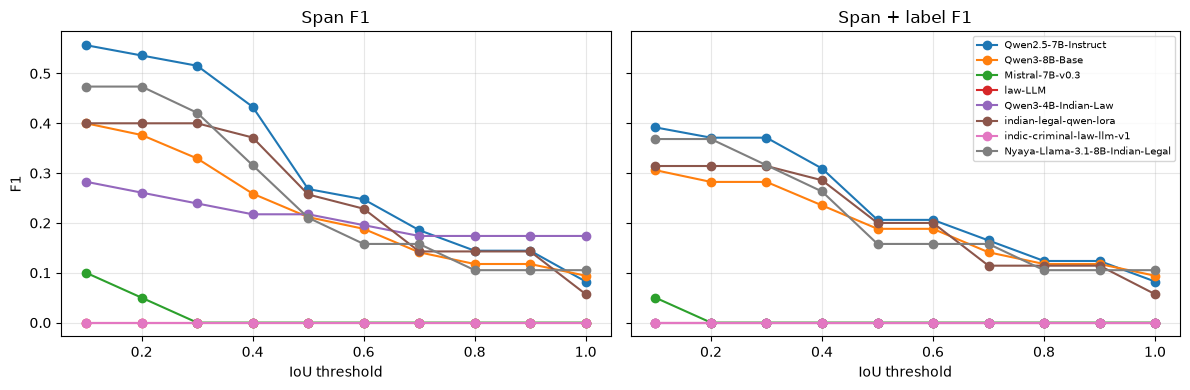

In [16]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a_, data, title in [(ax[0], sweep_span, "Span F1"), (ax[1], sweep_label, "Span + label F1")]:
    for llm, ys in data.items(): a_.plot(SWEEP, ys, marker="o", label=llm.split("/")[-1])
    a_.set_title(title); a_.set_xlabel("IoU threshold"); a_.grid(alpha=.3)
ax[0].set_ylabel("F1"); ax[1].legend(fontsize=7, loc="upper right")
plt.tight_layout(); plt.show()

## Inspect the matched pairs for one LLM and prompt

In [ ]:
def show_pairs(llm, prompt, thr=THRESHOLD):
    p = next(x for x in llm_data if x["llm_name"] == llm)
    sp = next(x for x in p["prompts"] if x["prompt_name"] == prompt)["llm_output"]
    gp = next(x for x in gold_data if x["prompt_name"] == prompt)["gold_output"]
    sysl = [s for s in sp if s["text_position"]]
    pairs = match_spans([tuple(s["text_position"]) for s in sysl], [tuple(g["text_position"]) for g in gp], thr)
    rows = [{"gold#": j, "sys#": i, "iou": round(v, 3), "gold_label": gp[j]["label"],
             "sys_label": canonical_label(sysl[i]["label"]), "same_label": gp[j]["label"] == canonical_label(sysl[i]["label"])}
            for i, j, v in pairs]
    matched_g = {r["gold#"] for r in rows}
    print(f"{len(rows)} matched of {len(gp)} gold / {len(sp)} system spans; unmatched gold: {[j for j in range(len(gp)) if j not in matched_g]}")
    return pd.DataFrame(rows)

show_pairs("Qwen/Qwen2.5-7B-Instruct", "strict_16_echr_labels_2000words")

4 matched of 21 gold / 27 system spans; unmatched gold: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 19, 20]


,gold#,sys#,iou,gold_label,sys_label,same_label
0,0,0,0.663,Application to the concrete case,Procedural arguments—Non contestation by the p...,False
1,16,14,1.000,Application to the concrete case,Application to the concrete case,True
2,17,16,0.777,Application to the concrete case,Application to the concrete case,True
3,18,17,1.000,Application to the concrete case,Application to the concrete case,True
